In [1]:
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

# Génération d'un dataset de classification binaire de test
X_raw, y_raw = make_classification(
    n_samples=2000, n_features=20, random_state=42
)
X = pd.DataFrame(X_raw)
y = pd.Series(y_raw)

# Découpage train/validation
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# --- 0. Récupération automatique du nombre de colonnes d'entrées ---
input_dim_class = X_train.shape[1]

# --- 1. Construction de l'architecture du réseau ---
model_class = keras.Sequential([
    layers.BatchNormalization(input_shape=[input_dim_class]),
    # Couche cachée 1
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.BatchNormalization(),
    # Couche cachée 2
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.BatchNormalization(),
    # Couche de sortie : 1 neurone avec 'sigmoid' pour la probabilité [0, 1]
    layers.Dense(1, activation='sigmoid'),
])

# --- 2. Compilation du modèle ---
model_class.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['binary_accuracy'],
)

# --- 3. Early Stopping ---
early_stopping = EarlyStopping(
    min_delta=0.001, patience=20, restore_best_weights=True
)

# --- 4. Entraînement du modèle ---
history_class = model_class.fit(
    X_train,
    y_train,
    validation_data=(X_valid, y_valid),
    batch_size=256,
    epochs=500,
    callbacks=[early_stopping],
    verbose=1,
)

Epoch 1/500


/usr/local/lib/python3.13/dist-packages/keras/src/layers/normalization/batch_normalization.py:142: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - binary_accuracy: 0.6963 - loss: 0.6247 - val_binary_accuracy: 0.8950 - val_loss: 0.4183
Epoch 2/500
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - binary_accuracy: 0.8606 - loss: 0.3604 - val_binary_accuracy: 0.9150 - val_loss: 0.3424
Epoch 3/500
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - binary_accuracy: 0.8781 - loss: 0.3169 - val_binary_accuracy: 0.9075 - val_loss: 0.3184
Epoch 4/500
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - binary_accuracy: 0.8900 - loss: 0.3080 - val_binary_accuracy: 0.9050 - val_loss: 0.3134
Epoch 5/500
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - binary_accuracy: 0.8856 - loss: 0.2798 - val_binary_accuracy: 0.8975 - val_loss: 0.3155
Epoch 6/500
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - binary_accuracy: 0.8875 - loss: 0.2780 - val_binary_accuracy: 0.8950 - val_loss: 0.3249
Epoch 7/500
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - binary_accuracy: 0.8856 - loss: 0.2711 - val_binary_accuracy: 0.8900 - val_loss: 0.3314
Epoch 8/500
7/7 ━━━━━━━━━━━━━━━━

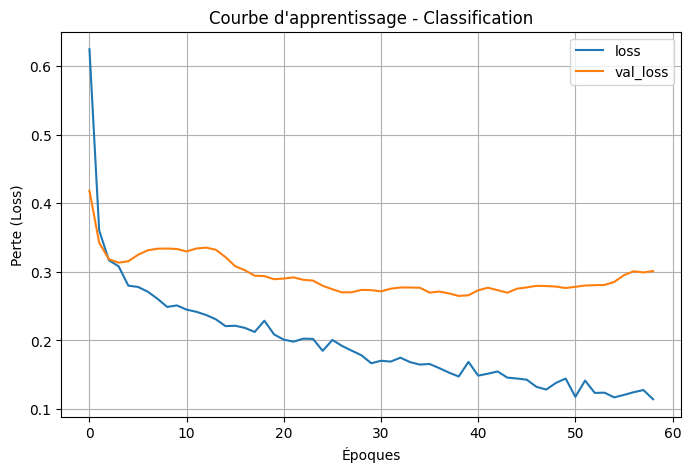

In [2]:
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history_class.history)
history_df.loc[:, ['loss', 'val_loss']].plot(figsize=(8, 5))
plt.title("Courbe d'apprentissage - Classification")
plt.xlabel("Époques")
plt.ylabel("Perte (Loss)")
plt.grid(True)
plt.show()